# 07 · RabbitMQ 消息可靠性与延迟任务（MQ高级）


## 本章来源与学习路线

本篇依据百度网盘 `我的资源/day07-MQ高级/PPT/MQ高级.pptx`。原 PPT **49 页**，第 **48、49 页隐藏**，网盘预览显示 **47 页**。笔记页码按原 PPT 顺序，隐藏页的分段延迟检查方案也纳入整理。整理日期：2026-10-09。

课件预览：[MQ高级](https://pan.baidu.com/pfile/docview?path=%2F%E6%88%91%E7%9A%84%E8%B5%84%E6%BA%90%2Fday07-MQ%E9%AB%98%E7%BA%A7%2FPPT%2FMQ%E9%AB%98%E7%BA%A7.pptx&fsid=209182719440722&size=660207&view_from=personal_file&md5=2b56aef9erc8fe0afe4d79142fc5754c&share=0&client=web&scene=main)。

| 阶段 | 原 PPT 页码 | 需要解决的问题 |
| --- | --- | --- |
| 发送者可靠性 | 4—12 | 连接失败、发送结果未知、路由失败 |
| Broker 可靠性 | 13—21 | 重启恢复、存储与积压 |
| 消费者可靠性 | 22—36 | 确认时点、失败重试、重复处理 |
| 延迟任务 | 37—49 | TTL、死信、延迟插件与超时关单 |

day07 资料目录包含 `rabbitmq_delayed_message_exchange-3.8.17.8f537ac.ez`。文件名只能说明课程提供了这个插件包，不能据此认定本机或 `mq.tar` 的实际 Broker 版本。本篇没有安装插件或启动系统。

示例延续上一篇已核对的 Demo 环境：Java 8 编译目标、Spring Boot 2.7.12 与 Spring AMQP 2.x API。“课件方案”来自材料，“整理示例”补足配置与业务契约，“补充/改进”说明课件的简化或版本边界。

补充核对了 [Spring AMQP 2.4 参考文档](https://docs.spring.io/spring-amqp/docs/2.4.x/reference/html/)，以及 RabbitMQ 当前 4.3 文档中的 [确认机制](https://www.rabbitmq.com/docs/confirms)、[Lazy Queue](https://www.rabbitmq.com/docs/lazy-queues)、[TTL](https://www.rabbitmq.com/docs/ttl)、[死信](https://www.rabbitmq.com/docs/dlx) 和[延迟插件上游说明](https://github.com/rabbitmq/rabbitmq-delayed-message-exchange)。新版本说明只用于校正边界，不能与旧课程配置无条件混用。


## 1. 消息可靠性是一条链路

支付库已经显示已支付，订单库却仍未支付，可能是发布、路由、存储或消费中的任一环节出了问题。（课件第 2 页）

```text
支付数据库提交
  → 发布消息
  → Broker 接收
  → 交换机路由到队列
  → 消息安全保存
  → 投递给消费者
  → 消费者业务数据库提交
  → 消费确认
```

| 环节 | 需要的机制 |
| --- | --- |
| 数据库与消息发布 | 待发送记录、重试、事务发件箱等 |
| 发布到 Broker | 发送重试、Publisher Confirm |
| 是否存在匹配队列 | Publisher Return / mandatory 与正确拓扑 |
| 队列保存与恢复 | 持久化、相应队列类型和可用副本 |
| 消费是否完成 | Consumer Acknowledgement |
| 处理失败或重复 | 有限重试、失败转存、幂等与业务补偿 |

可靠传递常需要允许重复，再用幂等保证业务效果。确认丢失时，“没有收到成功回执”可能意味着消息未到达，也可能意味着已到达但回执丢失。

> 发布确认和消费确认是两个独立协议阶段。Broker 对发送者 ACK，不代表订单服务已经完成数据库更新。


## 2. 发送重试与线程等待

网络波动导致连接或发送失败时，短暂重试可以提高成功率。（课件第 6 页）

**课件配置整理**：

```yaml
spring:
  rabbitmq:
    connection-timeout: 1s
    template:
      retry:
        enabled: true
        initial-interval: 1000ms
        multiplier: 1
        max-attempts: 3
```

| 配置 | 含义 |
| --- | --- |
| connection-timeout | 建立连接的超时，不是消费超时 |
| initial-interval | 第一次失败后的等待时间 |
| multiplier | 后续退避时间的倍数 |
| max-attempts=3 | 总尝试次数最多 3 次，包含首次调用 |

Spring Retry 的等待发生在当前发送线程，失败时会延长请求耗时。multiplier=1 表示相邻重试等待时间相同；使用倍增时还应设置合理的最大间隔。

这个配置给 RabbitTemplate 发送操作增加重试，不是无限后台重连，也不自动等待异步 Confirm 的最终结果。

改到异步线程只能转移请求等待，不能保证进程宕机后任务还在。需要可靠恢复时，应保存待发送事件；重发保留业务事件 ID，让消费者识别重复。


## 3. Publisher Confirm 与 Publisher Return

“Broker 收到”和“成功路由到队列”需要分别观察。（课件第 8、12 页）

| 机制 | 回答的问题 | 不能证明的结果 |
| --- | --- | --- |
| Publisher Confirm | Broker 是否接受并完成对应的发布处理 | 消费者业务是否完成 |
| Publisher Return | mandatory 消息是否因不可路由被退回 | 队列后续是否正常消费 |

对**普通交换机**启用 mandatory、Returns 与 Confirms 后，常见情况如下：

| 情况 | Return | Confirm |
| --- | --- | --- |
| 交换机存在，没有匹配队列 | 返回 NO_ROUTE 等原因 | 仍可能 ACK |
| 消息被匹配队列接受 | 通常没有 | ACK |
| 持久消息进入持久队列 | 通常没有 | 相应持久化条件满足后 ACK |
| Broker 无法完成发布处理 | 不一定 | 可能 NACK |
| 连接中断、交换机不存在等 | 不一定 | 可能异常、通道关闭、客户端产生失败结果或结果未知 |

不可路由消息的 Return 在相关发布确认之前发出。因此 **ACK + Return** 仍是目标队列未收到，不能当成业务发布成功。

课件说“其他情况都会 NACK”是简化。网络失败可能让应用始终拿不到回执；发布到不存在的交换机还可能直接关闭 Channel。需要把明确失败和结果未知都纳入恢复。


## 4. 开启确认与 mandatory

发送确认必须同时核对连接工厂、模板与实际发送 API。（课件第 9 页）

```yaml
spring:
  rabbitmq:
    publisher-confirm-type: correlated
    publisher-returns: true
    template:
      mandatory: true
```

前两项来自课件，mandatory 是为了明确不可路由消息的返回条件。RabbitTemplate 正常使用 Boot 自动配置时，这些参数会作用到相应组件；自行创建模板或连接工厂时要另外核对。

| confirm-type | 使用方式 |
| --- | --- |
| none | 不开启发布确认 |
| simple | 用确认模式通道，并通过适当的 waitForConfirms 等 API 等待结果 |
| correlated | 用 CorrelationData 或回调关联每次发布结果 |

配置为 simple 并不意味着每次 convertAndSend 自动阻塞到 Broker ACK。课件的“同步阻塞等待”描述的是对应使用方式，实际还要调用等待确认的 API。

publisher-returns=true 也不是“必定有返回”。普通不可路由返回还依赖 mandatory 条件，消费者抛异常不会触发 Publisher Return。


## 5. 全局注册 ReturnsCallback

每个 RabbitTemplate 只支持一个 ReturnsCallback，应在启动时统一注册，不能由每次发送随意覆盖。（课件第 10 页）

**整理示例**：

```java
@Configuration
@RequiredArgsConstructor
@Slf4j
public class PublisherReturnConfig {
    private final RabbitTemplate rabbitTemplate;

    @PostConstruct
    public void init() {
        rabbitTemplate.setReturnsCallback(returned -> {
            log.error(
                "消息不可路由：messageId={}, exchange={}, key={}, code={}, reason={}",
                returned.getMessage().getMessageProperties().getMessageId(),
                returned.getExchange(),
                returned.getRoutingKey(),
                returned.getReplyCode(),
                returned.getReplyText()
            );
        });
    }
}
```

RabbitTemplate 来自 `org.springframework.amqp.rabbit.core`。Boot 2.x 示例的 PostConstruct 来自 `javax.annotation`，不要直接混用 Boot 3 的 Jakarta import。

这里只演示观测。可靠发布还需要把返回结果关联到可恢复的待发送记录，而不能只打日志；若是绑定配置错误，立即无限重发同一个键也不会解决路由问题。


## 6. CorrelationData 与单次发布结果

异步回执可能乱序到达，需要用关联对象识别这次发送。（课件第 11 页）

**课程时期 API 的整理示例**：

```java
public void publish(PaySuccessEvent event) {
    String eventId = event.getEventId(); // 同一业务事件重发时保持稳定
    CorrelationData cd = new CorrelationData(
        eventId + "-" + UUID.randomUUID() // 每次发布尝试单独关联
    );

    cd.getFuture().addCallback(
        confirm -> {
            if (!confirm.isAck()) {
                log.error("发布 NACK：eventId={}, reason={}",
                    eventId, confirm.getReason());
            } else if (cd.getReturned() != null) {
                log.error("发布已 ACK 但不可路由：eventId={}", eventId);
            } else {
                log.info("Broker 发布阶段完成：eventId={}", eventId);
            }
        },
        failure -> log.error("发布回执异常：eventId={}", eventId, failure)
    );

    rabbitTemplate.convertAndSend(
        "pay.topic", "pay.success", event,
        message -> {
            message.getMessageProperties().setMessageId(eventId);
            message.getMessageProperties()
                .setDeliveryMode(MessageDeliveryMode.PERSISTENT);
            return message;
        },
        cd
    );
}
```

此方法片段放在注入 RabbitTemplate 且具有日志的发布组件中，PaySuccessEvent 延续上一篇消息契约。CorrelationData 来自 `org.springframework.amqp.rabbit.connection`，MessageDeliveryMode 来自 `org.springframework.amqp.core`。

Spring AMQP 2.x 的 Future 支持 addCallback；更新版本可能改为 CompletableFuture API，应按实际依赖调整。2.4 文档说明同时开启 Confirm/Return 并有唯一关联 ID 时，ReturnedMessage 会在该 Future 的 ACK 结果设置前写入。

| 标识 | 用途 |
| --- | --- |
| eventId / messageId | 识别业务事件与重复处理 |
| CorrelationData.id | 识别单次发布尝试和回执 |
| deliveryTag | 消费 Channel 上的投递序号，不是业务事件 ID |

异步回调中的异常不会自动让已经结束的支付事务回滚。待发送记录应有成功、明确失败和待确认状态，并用超时扫描处理没有回执的情况。


## 7. 确认机制的成本与业务选择

课件第 12 页提出发送确认有额外开销，并建议尽量避免。对于支付事件，应先以丢消息的业务成本判断需求。

| 消息 | 选择依据 |
| --- | --- |
| 支付成功、库存恢复 | 需要可观测、可恢复的发布结果 |
| 可丢弃的临时统计 | 可按容忍度选择较弱保障 |
| 大量可靠事件 | 优先异步处理确认、合理批量与容量设计 |

对 NACK 或回执超时可以有限重试，之后保存失败状态并进入恢复流程。回执超时属于未知结果，重发可能产生重复。

Confirm 的性能开销不构成支付通知直接关闭确认的理由。可靠性应由确认、持久化、消费者处理和兜底组成，而不是只靠某个开关。


## 8. 交换机、队列与消息持久化

Broker 重启后需要恢复拓扑和未完成消息，课件分别介绍三种持久化。（课件第 16、21 页）

| 对象 | 设置 | 保留的内容 |
| --- | --- | --- |
| Exchange | durable=true | 交换机定义 |
| Queue | durable=true | 队列定义 |
| Message | delivery mode=2 / PERSISTENT | 消息的持久化意图 |

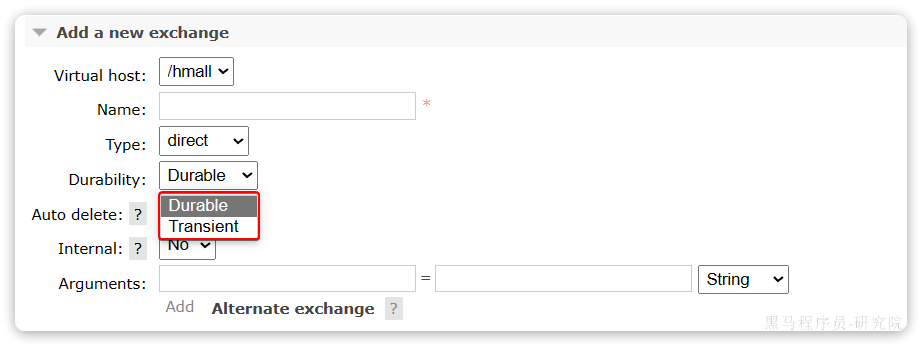

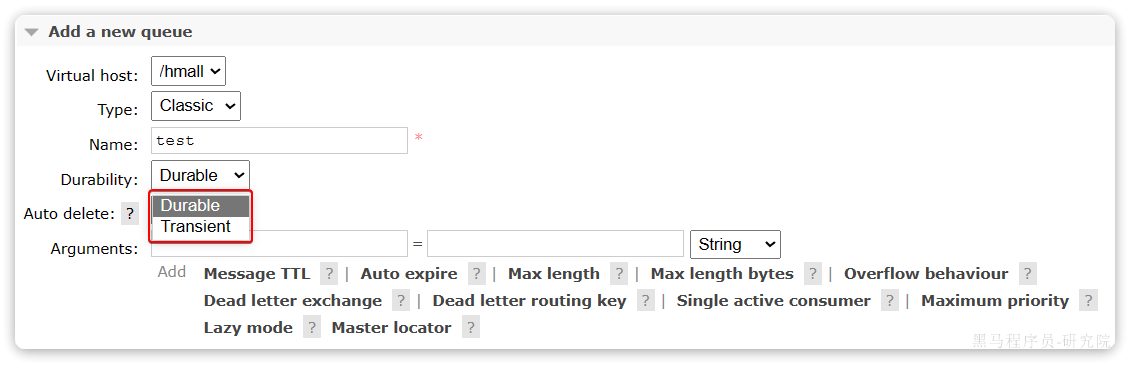

**整理示例**：

```java
@Bean
public DirectExchange reliableExchange() {
    return ExchangeBuilder.directExchange("reliable.direct")
        .durable(true).build();
}

@Bean
public Queue reliableQueue() {
    return QueueBuilder.durable("reliable.queue").build();
}
```

还需声明绑定关系并启用相应消息持久化。持久消息路由到普通持久队列后，发送确认提供该阶段持久化结果的证据；不同队列类型的接受与复制条件不同。

durable 的单节点队列不能抵抗永久丢失该节点磁盘。需要按要求选择复制能力，例如合适的 Quorum Queue 部署，并保留实际可用副本；PPT 没有展开集群配置。


## 9. 消息持久化不等于绝对不丢

课件控制台展示了 Delivery mode=1 和 2。应明确消息属性与队列定义分别作用于什么。

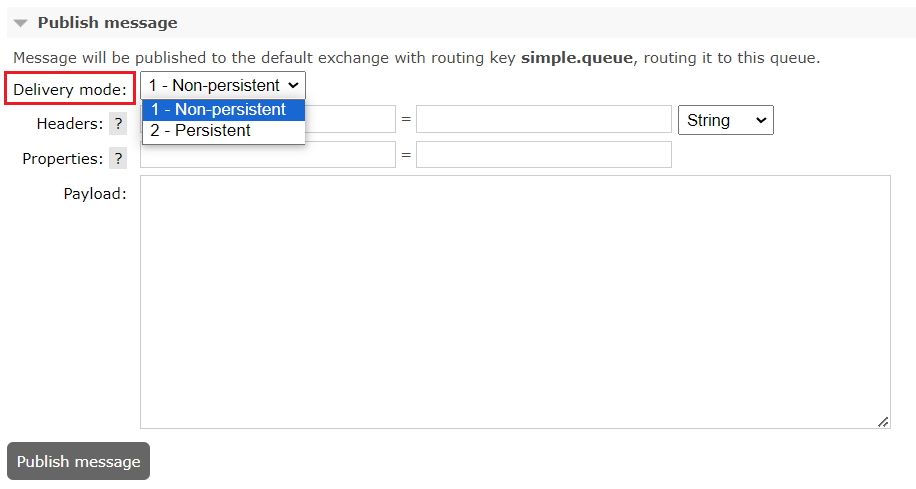

```java
rabbitTemplate.convertAndSend(
    "reliable.direct", "reliable", payload,
    message -> {
        message.getMessageProperties()
            .setDeliveryMode(MessageDeliveryMode.PERSISTENT);
        return message;
    }
);
```

Spring AMQP 的 MessageProperties 默认通常是 PERSISTENT，显式设置使示例意图清晰；不能因此忽略手工控制台、其他客户端或自定义转换器的属性。

| 误判 | 实际边界 |
| --- | --- |
| 队列 durable，消息就一定安全 | 仍需检查消息属性和发布结果 |
| 发布 API 正常返回，就已落盘 | 应观察对应发布确认 |
| 消息写过磁盘，就不会丢 | 节点磁盘永久故障、删除与配置错误仍可能丢失 |
| Broker ACK，业务一定成功 | 消费者还没有确认业务结果 |

异步发送与磁盘刷新存在时序，不能在收到对应确认前断言消息已经达到目标存储条件。


## 10. Lazy Queue 的旧用法与新版本边界

积压较多时，把大量消息留在内存会增加压力。旧版 Classic Queue 可选择 lazy 模式，倾向把消息放到磁盘。（课件第 18—21 页）

**旧课程环境的声明示例**：

```java
@Bean
public Queue lazyQueue() {
    return QueueBuilder.durable("lazy.queue")
        .lazy()
        .build();
}
```

注解方案的核心是队列参数 `x-queue-mode=lazy`：

```java
@RabbitListener(queuesToDeclare = @Queue(
    name = "lazy.queue",
    durable = "true",
    arguments = @Argument(name = "x-queue-mode", value = "lazy")
))
public void receiveLazy(String message) {
    log.info("收到 lazy.queue 消息：{}", message);
}
```

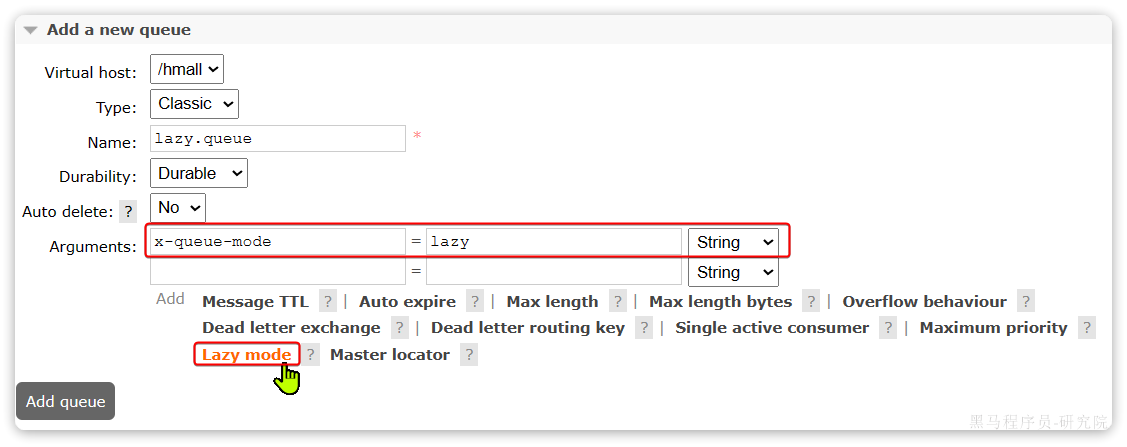

**版本校正**：官方当前文档说明，RabbitMQ 3.12 起不再支持旧的可切换 lazy 模式，该设置被忽略；当前 Classic Queue 的行为与旧 lazy 模式有相似之处，但不能写成“所有队列都变为 Lazy Queue”。

新版仍会短暂缓冲消息、保留部分消息在内存；已经快速投递并确认的消息可能不再写盘。课件的“完全不存内存”“最多 2048 条”不能当作所有版本的固定保证。

lazy / 磁盘存储策略不等于持久化消息属性或副本保障。磁盘也有容量和 IO 上限，消费者长期跟不上仍会积压。


## 11. 消费 ACK、NACK、Reject 与 requeue

消费者需要告诉 Broker 这次投递是否处理完成。（课件第 24 页）

| 方法 / 参数 | 结果 |
| --- | --- |
| basicAck | 确认完成，移除相应未确认投递 |
| basicNack(..., requeue=true) | 拒绝并重新入队，可支持 multiple |
| basicNack(..., requeue=false) | 不重新入原队列，配置 DLX 时进入死信流程，否则丢弃 |
| basicReject(..., requeue=true) | 拒绝单条并重新入队 |
| basicReject(..., requeue=false) | 拒绝单条，不重入原队列，可能死信或丢弃 |

课件把 NACK 直接对应再次投递、Reject 直接对应删除，是简化。**是否重新入队由 requeue 决定**，不是仅由方法名决定。

```text
业务提交成功 → ACK
暂时失败     → 有限重试 / 安排稍后处理
永久无效     → 不重入原队列，转失败流程
```

手动确认中的 deliveryTag 只在原 Channel 上有效。必须使用收到消息的同一 Channel 确认；重复 ACK 或在另一 Channel 上确认，可能触发 unknown delivery tag 并关闭通道。


## 12. Spring 的 NONE、AUTO 与 MANUAL

框架可以在监听方法外层管理确认，但需要选对模式与确认时点。（课件第 25 页）

| 模式 | 行为 | 使用判断 |
| --- | --- | --- |
| none | 使用 Broker 自动确认，不等待业务完成 | 只适用于允许丢失的处理 |
| auto | 容器根据监听执行与异常处理结果确认 | 常见业务默认选择 |
| manual | 业务代码显式 ACK / NACK / Reject | 需要自行管理确认生命周期 |

**AUTO 整理配置**：

```yaml
spring:
  rabbitmq:
    listener:
      simple:
        prefetch: 1
        acknowledge-mode: auto
```

Spring AUTO 不等于客户端 autoAck=true。课件将 AUTO 解释为 AOP 环绕增强，理解重点是监听容器及其拦截、异常处理链负责确认，不需要认为业务方法一定经过单独的 Spring AOP 代理。

异常的最终动作受 ErrorHandler、fatal 异常分类、重试 Recoverer 和 default-requeue-rejected 等共同影响，不能只按“业务异常 NACK、校验异常 Reject”硬记。

**MANUAL 的结构示例**：

```java
@RabbitListener(queues = "reliable.queue", ackMode = "MANUAL")
public void consume(Message message, Channel channel) throws IOException {
    long tag = message.getMessageProperties().getDeliveryTag();
    // 独立服务方法返回前已完成本地事务；失败需由约定的错误策略处理
    businessService.handle(message);
    channel.basicAck(tag, false);
}
```

Message 来自 `org.springframework.amqp.core`，Channel 来自 `com.rabbitmq.client`。手动模式还必须设计异常、通道中断和未确认消息的处理，以上不是完整错误恢复代码。

业务成功后、ACK 到达前宕机，消息仍可能重新投递。因此即便确认时点正确，也必须考虑幂等；把任务交给另一个线程后立即返回，还可能使 AUTO 在业务完成前确认。


## 13. 消费者本地重试与退避

不断 requeue 会造成快速失败、快速重新投递的循环，消耗 CPU 和网络。对短暂故障，可以先在消费端做有限重试。（课件第 27 页）

```yaml
spring:
  rabbitmq:
    listener:
      simple:
        prefetch: 1
        acknowledge-mode: auto
        retry:
          enabled: true
          initial-interval: 1000ms
          multiplier: 1
          max-attempts: 3
          stateless: true
```

max-attempts=3 包含首次处理，最多额外重试两次。无状态本地重试的等待占用当前消费执行线程，等待期间消息通常仍未确认，可能降低整体吞吐。

| 故障 | 适合的处理 |
| --- | --- |
| 短暂数据库 / 网络不可用 | 有限重试与退避 |
| 事件结构永远不合法 | 直接进入失败流程，避免重复无效尝试 |
| 外部依赖长期故障 | 延后重试、失败转存与人工恢复 |

**事务边界校正**：课件说“有事务就设 stateless=false”，过于简化。Spring AMQP 2.4 文档说明，事务在每次重试回调内开始时，无状态重试也可以适用；已有外层事务需要回滚并跨投递恢复时，才需要考虑有状态重试。

有状态重试需要稳定的消息识别键，例如 MessageId 或自定义 MessageKeyGenerator，还涉及事务管理器和容器配置。仅改一个 false，不能自动实现数据库与 MQ 的全局事务。


## 14. 重试耗尽后的 MessageRecoverer

重试需要明确出口，否则永远失败的消息会持续占用资源。（课件第 28—30 页）

| 实现 | 重试耗尽后的动作 | 风险 / 前提 |
| --- | --- | --- |
| RejectAndDontRequeueRecoverer | 拒绝，不重回原队列 | 配置 DLX 才能保留相应死信，否则可能丢弃 |
| ImmediateRequeueMessageRecoverer | 重新入队 | 可能重新进入无限失败循环 |
| RepublishMessageRecoverer | 发布到指定失败交换机 | 需失败拓扑与可靠转存设计 |

课件及 Boot 常见自动配置使用 RejectAndDontRequeueRecoverer；自定义容器或恢复器可能不同，不能把它视为所有 Spring Retry 场景的统一默认。

```text
业务队列 → 消费失败 → 有限本地重试
                     → 重试耗尽
                     → error.direct → error.queue
```

失败队列负责保留排查与恢复入口。把消息移进去不会自动修好订单，也不应让另一个消费者立即无限发送回原队列。


## 15. 失败转存与可靠恢复

课件第 29 页省略了失败拓扑声明，以下补齐交换机、队列、绑定与 Recoverer。

```java
@Configuration
public class ErrorMessageConfig {
    @Bean
    public DirectExchange errorExchange() {
        return new DirectExchange("error.direct", true, false);
    }

    @Bean
    public Queue errorQueue() {
        return QueueBuilder.durable("error.queue").build();
    }

    @Bean
    public Binding errorBinding(
            @Qualifier("errorQueue") Queue queue,
            @Qualifier("errorExchange") DirectExchange exchange) {
        return BindingBuilder.bind(queue).to(exchange).with("error");
    }

    @Bean
    public MessageRecoverer messageRecoverer(RabbitTemplate rabbitTemplate) {
        return new RepublishMessageRecoverer(
            rabbitTemplate, "error.direct", "error"
        );
    }
}
```

MessageRecoverer 和 RepublishMessageRecoverer 来自 `org.springframework.amqp.rabbit.retry`。Bean 由正常的 Boot 重试配置采用时才生效；手工创建监听容器的工程需显式接入。

Recoverer 成功返回后，原投递会按容器恢复结果结束；这是重新发布，不等同于 Broker 的死信机制。原消息从原队列移除前，失败转存必须有适当成功证据。

普通 RepublishMessageRecoverer 并不能仅靠“全局开启异步 Confirm”就保证它等待转存确认。Spring AMQP 2.3.3 起提供 RepublishMessageRecovererWithConfirms，可按相应版本配置等待确认或处理返回失败。

失败消息应保留稳定业务 ID、原交换机与路由键、异常分类和尝试次数，并限制诊断信息体积。重放前修复原因，重放时仍按原业务事件做幂等。


## 16. 为什么可靠消息仍会重复

幂等表示同一业务执行一次或多次，对业务状态的预期效果一致。（课件第 32 页）

```text
消费者提交订单更新
  → ACK 尚未到达 Broker
  → 连接中断
  → Broker 重新投递
  → 同一订单更新再次执行
```

| 操作 | 幂等判断 |
| --- | --- |
| 读取某个商品 | 通常不改变状态 |
| 将订单从未支付改为已支付 | 可结合条件更新做到幂等 |
| 每次 stock = stock - 1 | 重复会多扣库存 |
| 每次 balance = balance + amount | 重复会多退款 |

按 ID 删除记录通常可重复执行，但若同时发通知、写审计或释放资源，附加行为也要单独判断。

至少一次投递允许重复；幂等保证的是业务效果，不是让网络只发送一次。MQ 路由、消费确认和数据库唯一约束分别承担不同职责。


## 17. 消息 ID 去重与原子记录

课件第 33 页用消息 ID 判断重复，并提供自动创建 MessageId 的转换器配置：

```java
@Bean
public MessageConverter messageConverter() {
    Jackson2JsonMessageConverter converter =
        new Jackson2JsonMessageConverter();
    converter.setCreateMessageIds(true);
    return converter;
}
```

这能为转换产生的消息补充 ID，但业务代码重新构建并重发时，可能生成新 ID。**同一业务事件应在可靠存储中拥有稳定 eventId**，不能把每次新生成的传输 ID 当成业务去重键。

“先查询 ID，执行业务，最后单独保存 ID”还有两个漏洞：

| 漏洞 | 后果 |
| --- | --- |
| 两个消费者同时查到不存在 | 业务可能同时执行两次 |
| 业务已提交，保存 ID 前宕机 | 重新投递后再次执行 |

**补充：本地数据库的消费记录结构示例**：

```sql
CREATE TABLE consumed_event (
    consumer_name VARCHAR(64) NOT NULL,
    event_id VARCHAR(128) NOT NULL,
    processed_at DATETIME(6) NOT NULL,
    PRIMARY KEY (consumer_name, event_id)
) ENGINE = InnoDB;
```

使用 consumer_name 是为了让不同业务分别处理同一事件，不能因为订单服务处理过，就阻止通知服务处理。

```text
开始同一本地数据库事务
  → 用唯一键原子登记 consumer_name + event_id
  → 已有提交记录：识别为重复，结束
  → 首次登记：执行业务修改
  → 一起提交业务结果与消费记录

业务失败：一起回滚；下一次投递仍能重新处理
```

冲突处理要按数据库与持久化框架实现，只把真实唯一键冲突认定为重复；连接异常、约束错误等不能被笼统吞掉。记录与业务若位于不同数据库，上述本地原子性就不成立。

本地事务也不能直接覆盖外部短信、退款等副作用，这些接口还需稳定业务请求号与对应幂等协议。


## 18. 业务状态判断与条件更新

课件第 34—35 页让交易服务先判断订单是否未支付，再更新为已支付。这利用订单状态实现业务幂等。

**补充：把状态判断落实到原子更新条件**：

```sql
UPDATE orders
SET status = :paid_status, pay_time = :paid_at
WHERE id = :order_id AND status = :unpaid_status;
```

这里的命名参数是伪代码式绑定占位符，实际字段和状态值以工程为准。

| 结果 | 判断 |
| --- | --- |
| 更新 1 行 | 本次完成未支付到已支付的转换 |
| 更新 0 行，已支付且支付事实一致 | 重复事件，避免重复附加操作 |
| 更新 0 行，已取消或不存在 | 业务冲突，需要具体处理 |

仅“先查后改”会发生并发竞争。两个线程可能同时查到未支付，条件更新或相应锁机制才能保护最终状态转换。

订单状态幂等不自动保护积分、发券与退款。需要为每个副作用定义唯一业务动作，并把触发任务和状态变化一起可靠保存。


## 19. 支付一致性、发件箱与兜底扫描

课件第 36 页组合发布确认、持久化、消费确认、失败重试和幂等，并提出定期查询支付状态作为兜底。

```text
主流程：
支付成功 → 支付事件 → 交易服务幂等更新订单

恢复流程：
扫描长期未支付 / 状态待核对订单
  → 按订单号查询权威支付结果
  → 已支付：幂等更新
  → 查询失败或处理中：稍后核对
  → 超过业务期限：按关单协议处理
```

发布确认仍没有解决“支付库提交后、消息尚未发布时宕机”的窗口。可以采用上一篇介绍的事务发件箱：

| 阶段 | 关键动作 |
| --- | --- |
| 支付本地事务 | 一起保存支付状态和待发送事件 |
| 发布任务 | 发送已提交事件，观察 Confirm / Return |
| 发布失败或未知 | 保留事件，有限重试与扫描 |
| 交易消费者 | 本地事务内幂等更新 |
| 对账兜底 | 核对权威支付事实，补齐异常状态 |

Confirm 不能让数据库和 Broker 自动原子提交，Seata 的数据库模式也不意味着任意外部消息都已加入同一事务。

扫描应有分页、时间范围、频率、并发与监控，避免反复查询全部历史订单。查询超时不等于未支付，恢复动作仍要遵守订单状态机与支付截止策略。


## 20. 延迟消息与任务截止时间

订单创建时扣了库存，长期不付款就要关闭订单并释放库存。延迟消息提供稍后触发检查的机会。（课件第 38、46 页）

| 概念 | 含义 |
| --- | --- |
| 延迟消息 | 暂缓向业务消费队列路由或投递 |
| 延迟任务 | 在未来某时刻触发业务处理 |
| deadline / expireAt | 业务记录里的实际截止时间 |

```text
订单创建于 10:00，支付期限 15 分钟
  → expireAt = 10:15
  → 发布检查任务
  → 10:15 或之后收到
  → 重新核对订单与支付状态
```

消息可能因积压、故障或恢复而晚到，不能要求它精确在某一毫秒执行。业务必须保存绝对截止时间，消费时再次校验。

本篇主案例统一使用**15 分钟**，对应第 46—47 页；第 38 页和隐藏第 48 页的 30 分钟是另一组教学示意，不能混在一个实际配置中。


## 21. 死信与 Dead Letter Exchange

死信是队列中无法按正常方式继续保留或处理的消息。配置 DLX 后，可以把它重新发布到指定交换机。（课件第 40 页）

| 课件中的触发条件 | 准确理解 |
| --- | --- |
| 消费者拒绝 | basicReject / basicNack 且 requeue=false |
| 消息过期 | 队列或消息的 TTL 条件达到 |
| 队列达到长度限制 | 是否移除旧消息、拒绝新发布等取决于溢出策略 |

补充：特定版本的 Quorum Queue 还有 delivery-limit 触发条件。**队列自身过期被删除**不同于消息 TTL，整队列删除不自动把全部内容转成死信。

```text
normal.direct → normal.queue
                    │ 拒绝 / 消息过期 / 相应长度溢出
                    ▼
                dlx.direct → dlx.queue → 恢复或业务消费者
```

DLX 本身就是普通交换机，“死信”是源队列的转发配置和行为，不是必须创建特殊类型的交换机。

| 声明参数 | 对应 Policy 键 | 用途 |
| --- | --- | --- |
| x-dead-letter-exchange | dead-letter-exchange | 指定死信交换机 |
| x-dead-letter-routing-key | dead-letter-routing-key | 指定死信重新路由键 |

不配置新路由键时，通常沿用原路由键。DLX 与目标队列、绑定需要正确存在，并拥有相应权限，否则死信也可能丢失。

官方建议可变的运维设置优先用 Policy，避免把所有参数固定在应用声明里。普通 DLX 转发默认不能视为无损保证；支持条件下的 Quorum Queue 至少一次死信转发是另一个需显式配置的能力。


## 22. TTL + DLX 实现固定延迟

让消息在没有业务消费者的中间队列等待 TTL，过期后进入 DLX 的业务队列，即可形成延迟路径。

```text
发送 → normal.direct
  → normal.queue（消息 TTL 30 秒，无业务消费者）
  → 过期成为死信
  → dlx.direct
  → dlx.queue（业务消费者监听）
```

**补齐课件图示的拓扑示例**：

```java
@Configuration
public class TtlDelayConfig {
    @Bean
    public DirectExchange normalExchange() {
        return new DirectExchange("normal.direct", true, false);
    }

    @Bean
    public Queue normalQueue() {
        return QueueBuilder.durable("normal.queue")
            .ttl(30000)
            .deadLetterExchange("dlx.direct")
            .deadLetterRoutingKey("dead")
            .build();
    }

    @Bean
    public Binding normalBinding(
            @Qualifier("normalQueue") Queue queue,
            @Qualifier("normalExchange") DirectExchange exchange) {
        return BindingBuilder.bind(queue).to(exchange).with("normal");
    }

    @Bean
    public DirectExchange dlxExchange() {
        return new DirectExchange("dlx.direct", true, false);
    }

    @Bean
    public Queue dlxQueue() {
        return QueueBuilder.durable("dlx.queue").build();
    }

    @Bean
    public Binding dlxBinding(
            @Qualifier("dlxQueue") Queue queue,
            @Qualifier("dlxExchange") DirectExchange exchange) {
        return BindingBuilder.bind(queue).to(exchange).with("dead");
    }
}
```

发送端用 `rabbitTemplate.convertAndSend("normal.direct", "normal", payload)`；消费者监听 `dlx.queue`，而不是 normal.queue。中间队列一旦被业务消费者提前取走，消息可能不等到 TTL 就被处理。

ttl(30000) 是队列里的**消息 TTL**，对应 x-message-ttl，单位毫秒；它不是 x-expires，不会把整个队列设成 30 秒后删除。

以上声明参数是教学代码。改动已有队列的不可变参数可能产生冲突，实际环境迁移应采用合适的策略和运维计划。


## 23. 每条消息 TTL 与队头阻塞

不同任务需要不同等待时间时，可以设置消息的 expiration 属性，但它不构成任意时长都精确触发的定时器。

```java
rabbitTemplate.convertAndSend(
    "normal.direct", "normal", payload,
    message -> {
        message.getMessageProperties().setExpiration("5000");
        return message;
    }
);
```

消息 expiration 使用毫秒数字的**字符串**。队列和消息都设置 TTL 时，以较小值决定该消息在该队列的有效期。

```text
同一个中间队列，队头 → 队尾：
  A：TTL 30 分钟
  B：TTL 5 秒

B 已过期，但可能等到 A 离开队头后才被清理和死信转发
```

官方文档说明，Classic / Quorum Queue 的过期死信处理与消息到达队头等条件有关。因此混合 TTL 可能发生队头阻塞，不能承诺 B 5 秒后一定进入业务队列。

固定延迟可用不同 TTL 档位的队列，任意调度可使用适配版本的原生能力或外部调度与可靠存储。哪种方案合适，需要看延迟跨度、量级和恢复要求。


## 24. 延迟插件的原理与版本状态

课件第 42—44 页使用 delayed message 插件。它让交换机暂存消息，到期再按底层交换机规则路由。

| 名称 | 作用 |
| --- | --- |
| x-delayed-message | 插件提供的交换机类型 |
| x-delayed-type=direct / topic 等 | 实际采用的路由规则 |
| x-delay | 每条消息的延迟毫秒数 |

资料提供的 .ez 文件名为 3.8.17 系列。插件发布通常针对特定 RabbitMQ 系列，还要核对 Erlang 等要求，不能把旧包直接放到任意新 Broker。

**截至本篇整理日期的版本补充**：上游仓库在 **2026-09-24** 已归档，README 明确说明项目停止维护。这是课程旧方案的版本状态，不应把它作为新环境的通用默认部署方式。

上游说明该插件的延迟消息存于当前节点的单份磁盘副本，可恢复节点重启，但不能据此保证节点永久丢失后消息仍在；停用插件还会丢失尚未投递的延迟消息。它也不适合无界的大规模或长期调度。

插件不支持用 mandatory 保证**未来路由时**一定有目标队列。即便当前发布阶段成功，也不能推导出延迟结束时拓扑一定存在或最终业务一定完成。

保留课程实验时，安装顺序是核对版本、确定插件目录、复制匹配包、启用后再声明交换机。官方给出的查询与启用命令如下，仅作课程操作说明，本次未执行：

```shell
rabbitmq-plugins directories -s
rabbitmq-plugins enable rabbitmq_delayed_message_exchange
```


## 25. 声明与发送插件延迟消息

**课件 Bean 方式**：

```java
@Bean
public DirectExchange delayExchange() {
    return ExchangeBuilder.directExchange("delay.direct")
        .delayed()
        .durable(true)
        .build();
}
```

Spring 的 delayed 属性会让 RabbitAdmin 按插件类型和相应 x-delayed-type 声明。Broker 必须已经加载兼容插件。

**课件注解方式**：

```java
@RabbitListener(bindings = @QueueBinding(
    value = @Queue(name = "delay.queue", durable = "true"),
    exchange = @Exchange(
        name = "delay.direct",
        type = ExchangeTypes.DIRECT,
        durable = "true",
        delayed = "true"
    ),
    key = "delay"
))
public void receiveDelay(String message) {
    log.info("收到延迟消息：{}", message);
}
```

选择一套一致的拓扑声明即可。已存在同名普通 Direct 交换机时，不能直接把它按另一类型重新声明。

**发送整理示例**：

```java
rabbitTemplate.convertAndSend(
    "delay.direct", "delay", "hello, delayed message",
    message -> {
        message.getMessageProperties().setDelay(5000);
        return message;
    }
);
```

在课程时期 API 中，setDelay(5000) 设置消息头 x-delay，表示**延迟 5000 毫秒**，不是 expiration。课件第 44 页把它称为“过期时间”，需要与上一节消息 TTL 区分。

没有 x-delay 或不使用有效正延迟时，插件通常按相应规则直接路由。完整发送仍需消息契约、发布结果记录和任务兜底，不能只靠 durable=true。


## 26. 超时关单的业务判断

课件第 46—47 页要求下单后 15 分钟检查：已支付则同步订单，未支付则关单并恢复库存。

```text
收到订单检查消息
  → 读取本地订单
      ├── 已支付 → 结束
      ├── 已关闭 → 检查恢复任务是否完成
      └── 未支付
          → 查询权威支付状态
              ├── 已支付 → 幂等标记已支付
              ├── 查询失败 / 处理中 → 重试或进入核对流程
              └── 明确未支付
                  ├── 未到截止时间 → 再安排检查
                  └── 已到截止时间 → 按协议关单、安排库存恢复
```

先看本地状态可减少远程查询；本地未支付时，支付消息可能尚未到达，因此还需核对支付事实。

| 结果 | 能否直接关单 |
| --- | --- |
| 明确已支付 | 不能，应该同步支付状态 |
| 明确未支付且已过业务期限 | 还需按关单并发协议执行 |
| 超时、断网、支付处理中 | 不能当作未支付 |
| 本地订单已经关闭 | 不能再次无条件恢复库存 |

商品库存应对应本订单实际占用的明细和数量，不从延迟消息里任意相信新的扣减或恢复值。


## 27. 支付与关单并发、库存恢复

“查到未支付”与“关闭订单”之间可能发生支付。远程查询不是锁，也不能冻结支付状态。

```text
关单线程：查询支付服务 → 未支付 ─────→ 准备关单
支付线程：                  支付成功 → 发布事件

如果缺少协调，可能出现钱已扣、订单已关闭、库存已释放
```

**补充：本地关单条件更新思路**：

```sql
UPDATE orders
SET status = :closed_status, close_time = :now
WHERE id = :order_id
  AND status = :unpaid_status
  AND expire_at <= :now;
```

它保护订单库内的状态竞争，但单靠这条 SQL 仍无法防止支付库随后完成扣款。实际系统还要统一支付截止规则、关闭支付单或支付入口的协议，并定义迟到支付的核对、退款等恢复路径。

| 操作 | 可靠实现需要 |
| --- | --- |
| 关闭订单 | 只允许合法状态转换，记录实际胜出的结果 |
| 恢复库存 | 以 orderId 等稳定业务动作键保证只恢复一次 |
| 远程恢复失败 | 保留待恢复任务并重试，不只打日志 |
| 重复关单消息 | 识别已关闭，不重复释放库存 |

一种改进是：在订单关闭的**同一本地事务**中保存库存恢复事件或任务，再由消费者幂等处理。这样订单已关闭但调用库存前宕机时，还有恢复记录可查。

“已关闭”只是订单状态，不证明库存恢复已完成；事务任务记录、库存结果和监控共同提供证据。也可根据架构使用匹配的分布式事务或补偿流程，本篇不虚构完整关单源码。


## 28. 订单检查消息与绝对截止时间

PPT 没有给出取消订单的完整 DTO，以下是**整理消息契约**：

```json
{
  "taskId": "order-expire-1001",
  "orderId": 1001,
  "expireAt": "2026-10-09T10:15:00Z",
  "checkAttempt": 0
}
```

taskId 表示稳定业务任务，checkAttempt 用于检查进度和观测。expireAt 应与数据库约定一致，消费时仍以可信订单记录为准。

**插件课程环境中的首次发布片段**：

```java
rabbitTemplate.convertAndSend(
    "order.delay.direct", "order.check", orderCheckEvent,
    message -> {
        message.getMessageProperties().setDelay(15 * 60 * 1000);
        return message;
    }
);
```

orderCheckEvent 是整理契约，新增的 order.delay.direct / order.check 名称不是课件固定名称，需声明对应延迟交换机、队列与绑定才能使用。

示例假设在创建后及时发送。可靠重试或晚发布时应按 `expireAt - 当前时间` 计算剩余延迟，避免每次重发都再延长 15 分钟；已经到期的任务进入立即核对流程。

订单事务中保存检查任务、失败后重发、定时扫描逾期订单共同覆盖“订单已提交但延迟消息没有发出”的窗口。发送到异步线程不代替任务持久化。


## 29. 隐藏页：分段延迟检查

第 48—49 页提出：不必让每个已快速支付的订单都在 MQ 中等待完整 30 分钟，可以先短延迟检查，再按需要逐步延长。

课件图示使用 10 秒、15 秒、30 秒、1 分钟、2 分钟、5 分钟、10 分钟等档位。它们是阶段示意，不能忽略总业务期限，直接把所有重发时间机械累加。

```text
创建订单 → 短延迟检查
  ├── 已支付 → 结束检查
  └── 未支付且未到 deadline
       → 选择下一档延迟
       → 再次检查
       → 到 deadline 后进入关单协议
```

**调度伪代码**：

```text
remaining = expireAt - now
if remaining <= 0:
    核对并尝试关单
else:
    nextDelay = min(下一档检查间隔, remaining)
    可靠保存下一次检查任务，再发布
```

| 收益 | 新成本 |
| --- | --- |
| 已支付订单提前结束检查链 | 增加中间查询和消息次数 |
| 缩短一部分任务的占用时间 | 需要保存阶段、截止时间与重发状态 |
| 更早发现支付消息未同步 | 需要控制重复检查与查询压力 |

并不保证所有负载下都更省资源。高并发时应比较延迟任务积压、发布次数和支付查询成本；重复消息不能重复创建一整套新检查链。


## 30. 验证矩阵与故障排查

可靠性测试应观察事件记录、Broker 与数据库结果，而不只看一条“发送成功”日志。以下是验证设计，本次未执行故障注入。

| 场景 | 验证重点 |
| --- | --- |
| Broker 地址不可达 | 连接超时、发送尝试总次数、业务等待时间 |
| 普通交换机存在但 key 无匹配 | Return 与 ACK 同时出现，不能标成功 |
| 交换机不存在 | 通道异常和待发送恢复，不要求必有普通 NACK |
| 持久消息正常发布后重启 | 相应持久化条件、卷、消息与拓扑恢复 |
| 消费前后宕机 | 未确认消息重投递，业务不会重复变化 |
| 临时故障后恢复 | 有限重试成功，无无限 requeue |
| 永久无效消息 | 进入失败流程，保留原事件和诊断 |
| 两个消费者处理同一事件 | 唯一记录或状态条件保护业务 |
| 延迟消息晚到或重复 | 以截止时间和当前状态判断 |
| 查询支付超时 | 保留未知结果，不能直接关单 |
| 关单与支付并发 | 状态转换、迟到支付与库存恢复符合协议 |
| 关单后恢复库存失败 | 持久恢复任务仍可重试，重复不多加库存 |

| 现象 | 优先排查 |
| --- | --- |
| 只有 ACK，没有订单更新 | 是否 Return、消费异常、消费未启动或状态冲突 |
| Return 从未触发 | mandatory、publisher-returns、回调、普通或插件交换机 |
| 重试无限循环 | requeue、Recoverer、错误分类和退避 |
| unknown delivery tag | 错 Channel、重复确认、multiple 范围 |
| 改参数后 PRECONDITION_FAILED | 已有资源声明类型 / durable / arguments 不一致 |
| 新 Broker 中 lazy 不生效 | 版本已不再支持旧 lazy 模式 |
| 延迟交换机类型不存在 | 插件未启用或版本不兼容 |
| 5 秒 TTL 消息很晚进入 DLX | 中间队列的队头阻塞或实际积压 |
| 订单已关闭但库存未恢复 | 恢复任务、调用结果与补偿状态 |

监控至少覆盖：待发布事件数量与年龄、Confirm/Return 失败、ready/unacknowledged、消费失败与重试、失败队列、逾期检查任务、库存恢复待办。


## 31. 核心回顾与面试提示

| 主题 | 应掌握的边界 |
| --- | --- |
| 发布重试 | 可能阻塞，也可能造成重复 |
| Confirm / Return | 发布处理结果与不可路由结果不同 |
| ACK | 不能证明消费者业务完成，ACK + Return 仍未进目标队列 |
| 持久化 | 拓扑、消息、确认与副本分别检查 |
| Lazy Queue | 旧 Classic Queue 模式，新版本不能照搬 |
| 消费确认 | requeue 决定是否重入，确认应与业务完成一致 |
| 本地重试 | 总次数、退避、事务边界和耗尽出口 |
| MessageRecoverer | 拒绝、重入、转存，转存也需可靠 |
| 幂等 | 稳定业务 ID、唯一约束与业务状态机 |
| 消息与数据库 | 确认不自动解决原子提交窗口 |
| TTL + DLX | 消息过期触发转发，关注队头与转发失败 |
| 延迟插件 | 课程旧方案，核对维护状态与单副本边界 |
| 超时关单 | 截止时间、支付未知结果、并发与库存恢复 |
| 分段检查 | 短检查提前结束，阶段和总期限仍须持久化 |

**面试提示**：用支付成功事件串联“待发送记录 → Confirm/Return → 持久化 → 消费确认 → 有限重试 → 幂等 → 对账兜底”。解释 ACK 为什么仍可能路由失败，NACK/Reject 为什么还要看 requeue，业务已提交但 ACK 丢失为什么会重复。再比较 TTL + DLX 与延迟插件，说明消息晚到、支付查询未知和关单支付并发时，为什么不能直接恢复库存。
